# PAYGo portfolio analysis

Case Study 5, 04-782 Energy Data Analytics

**Question:** should an investor put money into this Nigerian PAYGo solar company, and on what terms?

**Data:** 25,685 contracts sold October 2023 to July 2026 and 275,172 monthly payment records, in naira (₦).
Payments run to 31 July 2026; contract status is from 10 August 2026.

**Method:** cleaning and checks from the TA starter notebook, then the five GOGLA KPIs for the whole portfolio,
cohort comparisons, drivers, open-book risk and a forecast. The decision is in Section 13.

## 0. Setup

Settings and plot style. The two CSVs go in `data/`; outputs go to `outputs/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, FuncFormatter, MultipleLocator
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
DATA_FOLDER = Path("data")
FIG_DIR = Path("outputs/figures")
TAB_DIR = Path("outputs/tables")
for folder in (FIG_DIR, TAB_DIR):
    folder.mkdir(parents=True, exist_ok=True)

FINANCIAL_DATE = pd.Timestamp("2026-07-31")       # last date of payment data
STATUS_DATE = pd.Timestamp("2026-08-10")          # date of status, due date and locked days
EXAMPLE_ID = 17112                                # lecture's worked contract
MIN_COHORT_SIZE = 100                             # GOGLA minimum per cohort
RECENT_WINDOW_START = pd.Timestamp("2025-08-01")  # start of the last 12 months

# GOGLA benchmarks from the lecture
BENCH_PVP_2X = {"Overall sample": 0.72, "West Africa": 0.77, "East Africa": 0.69}
BENCH_OR_2X = 0.78
GOGLA_ILLUSTRATIVE_TARGET = 0.80

# plot style
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
RAMP5 = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # oldest -> newest cohort
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110, "lines.linewidth": 1.8,
})
pct = PercentFormatter(1, decimals=0)
naira_m = FuncFormatter(lambda v, _: f"₦{v:,.0f}M")


def date_axis(ax):
    """Tick every January and July."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


def save_table(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    return df

## 1. Data checks

### 1.1 Load

In [3]:
contracts = pd.read_csv(DATA_FOLDER / "261113_contracts_vfinal.csv")
payments = pd.read_csv(DATA_FOLDER / "261113_payments_vfinal.csv")
for column in ["purchase_date", "paid_off_date", "payment_due_date"]:
    contracts[column] = pd.to_datetime(contracts[column], format="%m/%d/%y")  # dates are m/d/y
payments["payment_month"] = pd.to_datetime(payments["payment_month"])
print(f"{len(contracts):,} contracts; {len(payments):,} monthly payment records")
print(f"Sales from {contracts.purchase_date.min():%d %b %Y} to {contracts.purchase_date.max():%d %b %Y}; "
      f"payments from {payments.payment_month.min():%b %Y} to {payments.payment_month.max():%b %Y}")

25,685 contracts; 275,172 monthly payment records
Sales from 01 Oct 2023 to 31 Jul 2026; payments from Oct 2023 to Jul 2026


### 1.2 TA checks

Same checks as the TA notebook. Each `assert` stops the run if a result changes.

In [4]:
# keys, joins, signs and dates
assert contracts["contract_id"].is_unique
assert not payments.duplicated(["contract_id", "payment_month"]).any()
assert payments["contract_id"].isin(contracts["contract_id"]).all()
assert (payments["amount_paid"] > 0).all()
assert (payments["payment_month"] <= FINANCIAL_DATE).all() and payments["payment_month"].dt.is_month_start.all()

# ledger total vs snapshot total_paid
ledger_total = payments.groupby("contract_id")["amount_paid"].sum()
portfolio = contracts.copy()
portfolio["ledger_total"] = portfolio["contract_id"].map(ledger_total).fillna(0)
portfolio["payment_difference"] = portfolio["ledger_total"] - portfolio["total_paid"]
portfolio["reconciles"] = np.isclose(portfolio["payment_difference"], 0)
assert (~portfolio["reconciles"]).sum() == 341

# PAID_OFF status vs payoff date
payoff_conflict = (portfolio["contract_status"] == "PAID_OFF") != portfolio["paid_off_date"].notna()
assert portfolio.loc[payoff_conflict, "contract_id"].tolist() == [13843]

# missing segments become "Unknown"
missing = portfolio[["seller_type", "product_tier", "region"]].isna().sum()
assert missing.tolist() == [1476, 6429, 7914]
portfolio["seller"] = portfolio["seller_type"].fillna("Unknown")
portfolio["tier"] = portfolio["product_tier"].fillna("Unknown")
portfolio["region_f"] = portfolio["region"].fillna("Unknown")

# term = deposit days + financed days; blank due fields = not yet eligible
portfolio["term_days"] = portfolio["deposit_days"] + portfolio["financed_days"]
portfolio["day90_date"] = portfolio["purchase_date"] + pd.Timedelta(days=90)
portfolio["twice_term_date"] = portfolio["purchase_date"] + pd.to_timedelta(2 * portfolio["term_days"], unit="D")
assert (portfolio["day90_date"] <= FINANCIAL_DATE).equals(portfolio["due_at_90d"].notna())
assert (portfolio["twice_term_date"] <= FINANCIAL_DATE).equals(portfolio["due_at_2x"].notna())
print("Conflicting payment totals:", (~portfolio["reconciles"]).sum())
print("Reached day 90:", portfolio["due_at_90d"].notna().sum(), "| reached twice-term:", portfolio["due_at_2x"].notna().sum())
print("Missing:", missing.to_dict())

Conflicting payment totals: 341
Reached day 90: 23765 | reached twice-term: 4825
Missing: {'seller_type': 1476, 'product_tier': 6429, 'region': 7914}


### 1.3 Extra checks

In [5]:
# cash received in the month of sale
first_month = portfolio["purchase_date"].dt.to_period("M").dt.to_timestamp()
first_receipt = payments.merge(portfolio[["contract_id"]].assign(m=first_month), on="contract_id")
first_receipt = first_receipt.loc[first_receipt["payment_month"] == first_receipt["m"]].set_index("contract_id")["amount_paid"]
portfolio["first_month_cash"] = portfolio["contract_id"].map(first_receipt).fillna(0)
paid_off = portfolio["contract_status"] == "PAID_OFF"

extra_checks = pd.DataFrame([
    ("No payment rows", (portfolio["ledger_total"] == 0).sum(),
     "Kept with zero cash."),
    ("Zero deposit", (portfolio["deposit"] == 0).sum(),
     "Kept. Models Z28 (242) and Z34 (116)."),
    ("Sale-month cash below deposit", (portfolio["first_month_cash"] < portfolio["deposit"]).sum(),
     "Kept. Full deposit still subtracted (conservative)."),
    ("Ledger above contract price", (portfolio["ledger_total"] > portfolio["cash_price"]).sum(),
     "Overpayment. Removed by the cap at amount due."),
    ("Not PAID_OFF, ledger >= price", ((~paid_off) & (portfolio["ledger_total"] >= portfolio["cash_price"])).sum(),
     "All in the 341 conflicts. Ledger likely overstated."),
    ("PAID_OFF, snapshot below price", (paid_off & (portfolio["total_paid"] < portfolio["cash_price"])).sum(),
     "None. Payoff dates match receipts."),
    ("Schedule rebuilt exactly (2.1)", len(portfolio),
     "Matches due_to_date and due_at_90d."),
], columns=["Check", "Contracts", "Treatment"]).set_index("Check")
display(save_table(extra_checks, "data_checks_extra"))

conflicts = portfolio.loc[~portfolio["reconciles"]]
print(f"The 341 conflicts: ledger above snapshot in {(conflicts.payment_difference > 0).sum()}, "
      f"net ₦{conflicts.payment_difference.sum()/1e6:,.1f}M = "
      f"{conflicts.payment_difference.sum()/portfolio.ledger_total.sum():.2%} of all receipts")

,Contracts,Treatment
Check,,
No payment rows,8,Kept with zero cash.
Zero deposit,358,Kept. Models Z28 (242) and Z34 (116).
Sale-month cash below deposit,1056,Kept. Full deposit still subtracted (conservat...
Ledger above contract price,1974,Overpayment. Removed by the cap at amount due.
"Not PAID_OFF, ledger >= price",9,All in the 341 conflicts. Ledger likely overst...
"PAID_OFF, snapshot below price",0,None. Payoff dates match receipts.
Schedule rebuilt exactly (2.1),25685,Matches due_to_date and due_at_90d.


The 341 conflicts: ledger above snapshot in 339, net ₦4.0M = 0.12% of all receipts


Share of contracts with missing segments, by sales quarter. Most gaps are in early sales, so segment comparisons
(Section 9) hold the sales month fixed.

In [6]:
portfolio["cohort"] = portfolio["purchase_date"].dt.to_period("M")    # monthly sales cohort
portfolio["cohort_q"] = portfolio["purchase_date"].dt.to_period("Q")  # quarterly sales cohort
missing_by_q = portfolio.groupby("cohort_q")[["seller_type", "product_tier", "region"]].apply(lambda g: g.isna().mean())
display(save_table(missing_by_q.T.round(2), "missing_by_quarter"))

cohort_q,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
seller_type,0.270,0.160,0.150,0.100,0.060,0.040,0.020,0.000,0.000,0.000,0.000,0.000
product_tier,0.340,0.810,0.830,0.650,0.350,0.220,0.090,0.030,0.000,0.000,0.000,0.000
region,0.900,0.800,0.750,0.520,0.410,0.250,0.160,0.090,0.030,0.040,0.050,0.020


**Cleaning decisions**

| Issue | Treatment |
|---|---|
| Ledger vs snapshot totals (341 conflicts, ₦4.0M, 0.12% of cash) | Use the ledger, as the TA does. The snapshot changes PvP by 0.05 points. |
| Payoff-date conflict (13843) | Kept and flagged. |
| Missing channel, tier, region | "Unknown" group. |
| Applied payments | TA assumption: min(max(cash − deposit, 0), due). An estimate, not a GOGLA figure (no daily ledger). |
| Timing within a month | Lower and upper bounds (TA), plus a pro-rata midpoint. |
| Exclusions | None. All 25,685 contracts and all statuses. |

## 2. Measurement

### 2.1 Rebuild the original schedule

The `due_*` fields give the schedule at three dates only. This rule reproduces them exactly: after the deposit days,
one instalment falls due at the start of each period (7 days, or 1 day for the 491 daily plans), capped at the
amount financed.

In [7]:
n_instalments = np.ceil(portfolio["amount_financed"] / portfolio["instalment"] - 1e-9)
portfolio["period_days"] = np.where((portfolio["financed_days"] / n_instalments).round() == 1, 1, 7)  # daily or weekly


def due_at(frame, days):
    """Instalments due `days` after purchase under the original schedule (no deposit)."""
    days = np.asarray(days, dtype=float) * np.ones(len(frame))
    n_due = np.floor((days - frame["deposit_days"].to_numpy()) / frame["period_days"].to_numpy()) + 1
    n_due = np.where(days < frame["deposit_days"].to_numpy(), 0, n_due)  # nothing due during deposit days
    return np.minimum(np.clip(n_due, 0, None) * frame["instalment"].to_numpy(), frame["amount_financed"].to_numpy())


age_at_report = (FINANCIAL_DATE - portfolio["purchase_date"]).dt.days
assert np.allclose(due_at(portfolio, age_at_report), portfolio["due_to_date"])
has90 = portfolio["due_at_90d"].notna()
assert np.allclose(due_at(portfolio, 90)[has90], portfolio.loc[has90, "due_at_90d"])
print("Rebuilt schedule matches due_to_date and due_at_90d for all", len(portfolio), "contracts")
print("Payment plans:", portfolio["period_days"].map({7: "weekly", 1: "daily"}).value_counts().to_dict())

Rebuilt schedule matches due_to_date and due_at_90d for all 25685 contracts
Payment plans: {'weekly': 25194, 'daily': 491}


### 2.2 Cumulative cash and the measurement function

- `cum_cash`: cumulative receipts per contract at each month end.
- `measure_at(days)`: measures each contract at its own cutoff (e.g. day 90). Not yet reached = NaN, not zero.
- `summarize`: adds amounts within groups before dividing (GOGLA rule).

In [8]:
MONTHS = pd.period_range(portfolio["cohort"].min(), FINANCIAL_DATE.to_period("M"), freq="M")
monthly_cash = (payments.assign(month=payments["payment_month"].dt.to_period("M"))
                .pivot_table(index="contract_id", columns="month", values="amount_paid", aggfunc="sum")
                .reindex(index=portfolio["contract_id"], columns=MONTHS).fillna(0))  # contract x month
cum_cash = monthly_cash.cumsum(axis=1).to_numpy()
month_index = {m: i for i, m in enumerate(MONTHS)}
deposit = portfolio["deposit"].to_numpy(dtype=float)
financed = portfolio["amount_financed"].to_numpy(dtype=float)
rows_all = np.arange(len(portfolio))


def applied(cash, due):
    """TA assumption: cash after the deposit, capped at instalments due."""
    return np.minimum(np.clip(cash - deposit, 0, None), due)


def measure_at(days):
    days = np.asarray(days, dtype=float) * np.ones(len(portfolio))
    cutoff = portfolio["purchase_date"] + pd.to_timedelta(days, unit="D")
    eligible = (cutoff <= FINANCIAL_DATE).to_numpy()
    col = np.array([month_index.get(m, len(MONTHS) - 1) for m in cutoff.dt.to_period("M")])
    cash_before = np.where(col > 0, cum_cash[rows_all, np.clip(col - 1, 0, None)], 0.0)  # lower: before cutoff month
    cash_through = cum_cash[rows_all, col]                                                 # upper: incl. cutoff month
    share_of_month = (cutoff.dt.day / cutoff.dt.days_in_month).to_numpy()
    cash_mid = cash_before + (cash_through - cash_before) * share_of_month                 # pro-rata midpoint
    due = due_at(portfolio, days)
    out = pd.DataFrame({"contract_id": portfolio["contract_id"].to_numpy(), "eligible": eligible, "due": due,
                        "cutoff": cutoff.to_numpy()})
    for name, cash in [("lower", cash_before), ("mid", cash_mid), ("upper", cash_through)]:
        out[f"applied_{name}"] = np.where(eligible, applied(cash, due), np.nan)
    out["owned"] = np.where(eligible, (portfolio["paid_off_date"] <= cutoff).to_numpy(), np.nan)
    return out


def summarize(measured, by, frame=None):
    """Sum amounts and count contracts per group, then divide."""
    frame = portfolio if frame is None else frame
    rows = measured.loc[measured["eligible"]].merge(frame, on="contract_id", suffixes=("", "_c"))
    g = rows.groupby(by, observed=True)
    out = g[["due", "applied_lower", "applied_mid", "applied_upper"]].sum()
    out.insert(0, "contracts", g.size())
    for name in ["lower", "mid", "upper"]:
        out[f"pvp_{name}"] = out[f"applied_{name}"] / out["due"]
    out["ownership"] = g["owned"].mean()
    return out

### 2.3 Check against the TA's worked numbers

In [9]:
m90 = measure_at(90)
m2x = measure_at(2 * portfolio["term_days"].to_numpy())

# contract 2 at day 90: 72.4% to 83.6%
c2 = m90.set_index("contract_id").loc[2]
assert np.isclose(c2.applied_lower / c2.due, 15591 / 21538) and np.isclose(c2.applied_upper / c2.due, 17999 / 21538)

# contract 17112 today: 57.3%
now_applied = applied(portfolio["ledger_total"].to_numpy(), portfolio["due_to_date"].to_numpy())
ex = portfolio["contract_id"] == EXAMPLE_ID
assert np.isclose(now_applied[ex][0], 62872) and np.isclose(now_applied[ex][0] / 109648, 0.5734, atol=5e-5)
assert m2x["eligible"].sum() == 4825

# Z17, Oct-Dec 2023 sales at twice-term
z17_early = portfolio["model_code"].eq("Z17") & portfolio["cohort"].astype(str).between("2023-10", "2023-12")
ta_2x = summarize(m2x, "cohort", portfolio.loc[z17_early])
assert np.allclose(ta_2x["pvp_lower"].round(4), [0.9740, 0.9648, 0.9595])
assert np.allclose(ta_2x["pvp_upper"].round(4), [0.9742, 0.9665, 0.9613])
assert ta_2x["contracts"].tolist() == [384, 449, 380]
assert np.allclose((ta_2x["ownership"] * ta_2x["contracts"]).round().tolist(), [346, 397, 334])
display(ta_2x[["contracts", "pvp_lower", "pvp_upper", "ownership"]])
print("TA results reproduced.")

,contracts,pvp_lower,pvp_upper,ownership
cohort,,,,
2023-10,384,0.974,0.974,0.901
2023-11,449,0.965,0.966,0.884
2023-12,380,0.960,0.961,0.879


TA results reproduced.


## 3. The company

Sales volume and product mix over time.

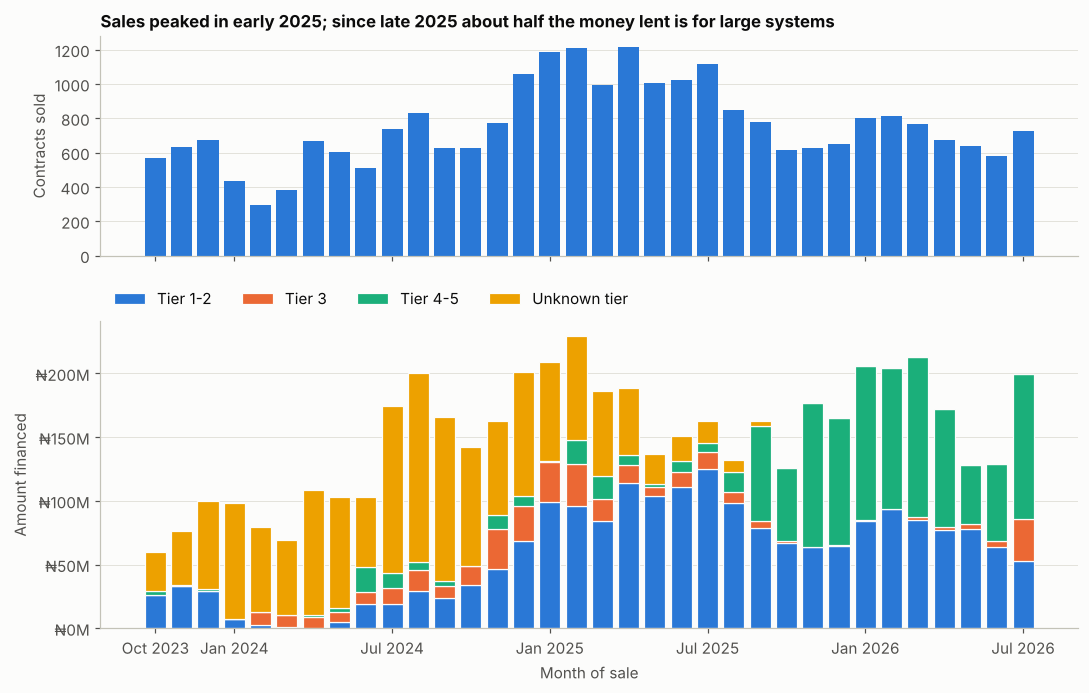

In [10]:
portfolio["tier_group"] = np.select(
    [portfolio["tier"].isin(["Tier 1", "Tier 2"]), portfolio["tier"].eq("Tier 3"),
     portfolio["tier"].isin(["Tier 4", "Tier 5"])],
    ["Tier 1-2", "Tier 3", "Tier 4-5"], default="Unknown tier")
portfolio["deposit_share"] = portfolio["deposit"] / portfolio["cash_price"]

sales = (portfolio.pivot_table(index="cohort", columns="tier_group", values="amount_financed", aggfunc="sum")
         .reindex(columns=["Tier 1-2", "Tier 3", "Tier 4-5", "Unknown tier"]).fillna(0) / 1e6)  # ₦M per month
counts = portfolio.groupby("cohort").size()

fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
x = np.arange(len(sales))
axes[0].bar(x, counts.to_numpy(), width=0.8, color=BLUE)
axes[0].set_ylabel("Contracts sold")
axes[0].set_title("Sales peaked in early 2025; since late 2025 about half the money lent is for large systems")
bottom = np.zeros(len(sales))
for colour, group in zip([BLUE, ORANGE, AQUA, YELLOW], sales.columns):
    axes[1].bar(x, sales[group], bottom=bottom, width=0.8, color=colour, label=group, edgecolor=SURFACE, linewidth=0.8)
    bottom += sales[group].to_numpy()
axes[1].yaxis.set_major_formatter(naira_m)
axes[1].set_ylabel("Amount financed")
axes[1].legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ticks = [i for i, p in enumerate(sales.index) if p.month in (1, 7) or i == 0]
axes[1].set_xticks(ticks, [sales.index[i].strftime("%b %Y") for i in ticks])
axes[1].set_xlabel("Month of sale")
fig.tight_layout()
savefig(fig, "fig1_sales_and_mix")
plt.show()

In [11]:
# quarterly mix: size, product, deposit, channel
mix = portfolio.groupby("cohort_q").apply(lambda g: pd.Series({
    "contracts": len(g),
    "financed ₦M": g["amount_financed"].sum() / 1e6,
    "avg financed ₦k": g["amount_financed"].mean() / 1e3,
    "Tier 4-5 share of ₦": g.loc[g["tier_group"] == "Tier 4-5", "amount_financed"].sum() / g["amount_financed"].sum(),
    "zero-deposit share of ₦": g.loc[g["deposit"] == 0, "amount_financed"].sum() / g["amount_financed"].sum(),
    "median deposit % of price": g["deposit_share"].median(),
    "agent share": (g["seller"] == "agent").mean(),
    "staff share": (g["seller"] == "staff").mean(),
}), include_groups=False)
display(save_table(mix, "sales_mix_by_quarter"))

,contracts,financed ₦M,avg financed ₦k,Tier 4-5 share of ₦,zero-deposit share of ₦,median deposit % of price,agent share,staff share
cohort_q,,,,,,,,
2023Q4,"1,871.000",236.494,126.400,0.024,0.000,0.070,0.516,0.214
2024Q1,"1,110.000",247.406,222.888,0.000,0.000,0.079,0.584,0.259
2024Q2,"1,779.000",314.553,176.814,0.082,0.000,0.052,0.589,0.265
2024Q3,"2,195.000",540.308,246.154,0.042,0.000,0.079,0.521,0.384
2024Q4,"2,457.000",506.482,206.139,0.037,0.000,0.061,0.572,0.371
2025Q1,"3,391.000",623.952,184.002,0.060,0.048,0.039,0.530,0.435
2025Q2,"3,246.000",476.265,146.724,0.040,0.017,0.039,0.663,0.320
2025Q3,"2,742.000",456.832,166.605,0.213,0.009,0.039,0.743,0.254
2025Q4,"1,894.000",467.962,247.076,0.575,0.188,0.039,0.817,0.180


- Sales peaked at 1,100–1,200 contracts a month in early 2025; now 600–800.
- Z37 (Tier 2, launched February 2025) overtook Z17 (Tier 1) as the main product in 2026.
- Since Q4 2025, Tier 4–5 systems (₦0.34–4.3M) are 46–58% of money lent. Zero-deposit loans (mainly Z34) were
  19–23% in Q4 2025–Q1 2026.
- Median deposit for recent sales: 3.4–4% of the price.
- Staff sold 44% of contracts in Q1 2025 and none in July 2026.

Status on 10 August 2026:

In [12]:
status_table = pd.crosstab(portfolio["cohort_q"], portfolio["contract_status"], margins=True, margins_name="All")
status_share = status_table.div(status_table["All"], axis=0).drop(columns="All")
display(save_table(status_share.round(3), "status_by_quarter"))
active = portfolio["contract_status"].isin(["ON", "LOCKED"])
print(f"Active (ON or LOCKED): {active.sum():,}; of these LOCKED: {(portfolio.loc[active, 'contract_status'] == 'LOCKED').mean():.1%}")
print(f"Fully paid (owned): {paid_off.sum():,} ({paid_off.mean():.1%}); repossessed: "
      f"{(portfolio.contract_status == 'REPOSSESSED').sum():,} ({(portfolio.contract_status == 'REPOSSESSED').mean():.1%})")

contract_status,LOCKED,ON,PAID_OFF,REPOSSESSED
cohort_q,,,,
2023Q4,0.089,0.002,0.901,0.008
2024Q1,0.157,0.020,0.798,0.025
2024Q2,0.216,0.014,0.734,0.037
2024Q3,0.306,0.083,0.584,0.026
2024Q4,0.339,0.116,0.515,0.029
2025Q1,0.400,0.162,0.405,0.033
2025Q2,0.435,0.266,0.248,0.051
2025Q3,0.425,0.458,0.077,0.040
2025Q4,0.365,0.559,0.025,0.052


Active (ON or LOCKED): 15,885; of these LOCKED: 51.2%
Fully paid (owned): 8,875 (34.6%); repossessed: 925 (3.6%)


## 4. KPIs 1–2: Paid vs Plan and Paid vs Financed

PvP = applied ÷ due to date. PvFin = applied ÷ amount financed. Measured at 31 July 2026, a month end, so there is
no timing range.

In [13]:
portfolio["applied_now"] = now_applied
pvp_now = portfolio["applied_now"].sum() / portfolio["due_to_date"].sum()
pvfin_now = portfolio["applied_now"].sum() / portfolio["amount_financed"].sum()
snapshot_applied = applied(portfolio["total_paid"].to_numpy(), portfolio["due_to_date"].to_numpy())  # sensitivity
pvp_snapshot = snapshot_applied.sum() / portfolio["due_to_date"].sum()
print(f"Portfolio PvP at 31 Jul 2026: {pvp_now:.1%} (snapshot cash instead of ledger: {pvp_snapshot:.1%})")
print(f"Portfolio PvFin at 31 Jul 2026: {pvfin_now:.1%}")
print(f"Instalments due but not paid (cumulative arrears): ₦{(portfolio.due_to_date - portfolio.applied_now).sum()/1e6:,.0f}M")

by_q = portfolio.groupby("cohort_q").agg(contracts=("contract_id", "size"), applied=("applied_now", "sum"),
                                         due=("due_to_date", "sum"), financed=("amount_financed", "sum"))
by_q["PvP"] = by_q["applied"] / by_q["due"]
by_q["PvFin"] = by_q["applied"] / by_q["financed"]
display(save_table(by_q[["contracts", "PvP", "PvFin"]], "pvp_pvfin_by_quarter"))

Portfolio PvP at 31 Jul 2026: 76.4% (snapshot cash instead of ledger: 76.4%)
Portfolio PvFin at 31 Jul 2026: 57.7%
Instalments due but not paid (cumulative arrears): ₦912M


,contracts,PvP,PvFin
cohort_q,,,
2023Q4,1871,0.950,0.950
2024Q1,1110,0.913,0.913
2024Q2,1779,0.885,0.885
2024Q3,2195,0.800,0.799
2024Q4,2457,0.768,0.768
2025Q1,3391,0.713,0.696
2025Q2,3246,0.667,0.637
2025Q3,2742,0.668,0.548
2025Q4,1894,0.693,0.408


Portfolio PvP at each month end:

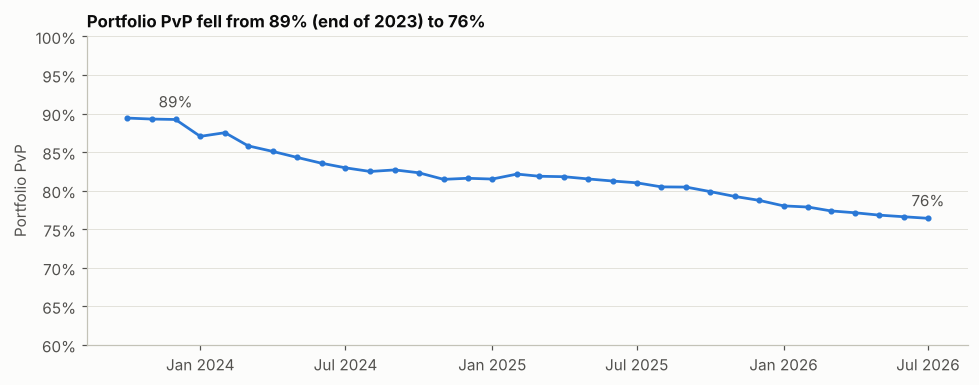

In [14]:
rows = []
for i, month in enumerate(MONTHS):
    month_end = month.to_timestamp(how="end").normalize()
    live = (portfolio["purchase_date"] <= month_end).to_numpy()          # contracts sold by then
    due_m = due_at(portfolio, (month_end - portfolio["purchase_date"]).dt.days.to_numpy())
    app_m = applied(cum_cash[:, i], due_m)
    rows.append({"month": month, "contracts": live.sum(), "due": due_m[live].sum(), "applied": app_m[live].sum()})
pvp_series = pd.DataFrame(rows).set_index("month")
pvp_series["PvP"] = pvp_series["applied"] / pvp_series["due"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(pvp_series.index.to_timestamp(), pvp_series["PvP"], color=BLUE, marker="o", markersize=3)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Portfolio PvP")
ax.set_title("Portfolio PvP fell from 89% (end of 2023) to 76%")
date_axis(ax)
for month in [MONTHS[2], MONTHS[-1]]:
    ax.annotate(f"{pvp_series.loc[month, 'PvP']:.0%}", (month.to_timestamp(), pvp_series.loc[month, "PvP"]),
                textcoords="offset points", xytext=(0, 8), ha="center", color=INK2)
fig.tight_layout()
savefig(fig, "fig2_portfolio_pvp")
plt.show()

Portfolio PvP is 76.4%. Some of the fall is expected: PvP dips mid-term, and a young book has many contracts there.
Section 5 compares cohorts at the same stage instead.

## 5. Cohorts at the same stage of the term

PvP at every 5% of each contract's term, summed by sales quarter. A point is shown only if at least 100 contracts
and half the cohort's money have reached it. Right panel: Z17 only (one product, one 406-day term).

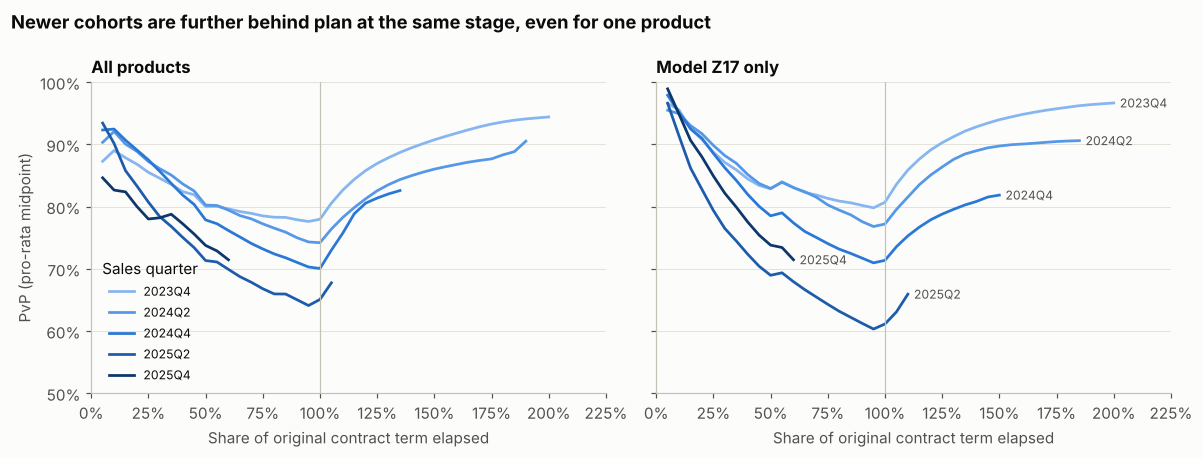

In [15]:
GRID_STEPS = np.round(np.arange(0.05, 2.0001, 0.05), 2)                        # 5% ... 200% of term
grid_measures = {k: measure_at(k * portfolio["term_days"].to_numpy()) for k in GRID_STEPS}


def vintage_table(mask=None, by="cohort_q", min_share=0.5):
    """PvP (midpoint) by cohort at each grid step; blank if too few contracts or too little money has reached it."""
    frame = portfolio if mask is None else portfolio.loc[mask]
    cohort_financed = frame.groupby(by)["amount_financed"].sum()
    out = {}
    for k, measured in grid_measures.items():
        s = summarize(measured, by, frame)
        reached = (measured.loc[measured["eligible"], ["contract_id"]]
                   .merge(frame[["contract_id", by, "amount_financed"]], on="contract_id")
                   .groupby(by)["amount_financed"].sum())
        share = (reached / cohort_financed).reindex(s.index)
        out[k] = s["pvp_mid"].where((s["contracts"] >= MIN_COHORT_SIZE) & (share >= min_share))
    return pd.DataFrame(out)


vintage_all = vintage_table()
vintage_z17 = vintage_table(portfolio["model_code"] == "Z17")
show_q = [pd.Period(q) for q in ["2023Q4", "2024Q2", "2024Q4", "2025Q2", "2025Q4"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, table, title in [(axes[0], vintage_all, "All products"), (axes[1], vintage_z17, "Model Z17 only")]:
    for colour, q in zip(RAMP5, show_q):
        series = table.loc[q].dropna()
        ax.plot(series.index, series.to_numpy(), color=colour, label=str(q))
        if ax is axes[1]:
            ax.annotate(str(q), (series.index[-1], series.iloc[-1]), textcoords="offset points", xytext=(4, 0),
                        va="center", fontsize=8, color=INK2)
    ax.axvline(1.0, color=AXIS, linewidth=0.8)   # end of original term
    ax.set_title(title)
    ax.set_xlabel("Share of original contract term elapsed")
    ax.xaxis.set_major_formatter(pct)
    ax.set_xlim(0, 2.25)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_ylabel("PvP (pro-rata midpoint)")
axes[0].legend(title="Sales quarter", loc="lower left", fontsize=8)
fig.suptitle("Newer cohorts are further behind plan at the same stage, even for one product",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig3_vintage_curves")
plt.show()

In [16]:
checkpoints = [0.3, 0.5, 0.7, 0.9, 1.0, 1.5, 2.0]
display(Markdown("**PvP by share of term elapsed, Z17**"))
display(save_table(vintage_z17[checkpoints].dropna(how="all"), "vintage_z17"))
display(Markdown("**PvP by share of term elapsed, all products**"))
display(save_table(vintage_all[checkpoints].dropna(how="all"), "vintage_all"))

**PvP by share of term elapsed, Z17**

,0.300,0.500,0.700,0.900,1.000,1.500,2.000
cohort_q,,,,,,,
2023Q4,0.871,0.828,0.819,0.802,0.807,0.940,0.967
2024Q1,0.816,0.762,0.761,0.738,0.741,0.872,0.916
2024Q2,0.882,0.829,0.815,0.776,0.772,0.897,NaN
2024Q3,0.868,0.809,0.772,0.730,0.728,0.842,NaN
2024Q4,0.862,0.785,0.750,0.717,0.714,0.818,NaN
2025Q1,0.811,0.733,0.697,0.660,0.655,NaN,NaN
2025Q2,0.765,0.690,0.655,0.612,0.611,NaN,NaN
2025Q3,0.765,0.690,0.652,NaN,NaN,NaN,NaN
2025Q4,0.821,0.738,NaN,NaN,NaN,NaN,NaN


**PvP by share of term elapsed, all products**

,0.300,0.500,0.700,0.900,1.000,1.500,2.000
cohort_q,,,,,,,
2023Q4,0.845,0.800,0.789,0.779,0.780,0.907,0.944
2024Q1,0.837,0.785,0.767,0.751,0.746,0.873,0.911
2024Q2,0.861,0.802,0.780,0.750,0.742,0.860,NaN
2024Q3,0.857,0.792,0.755,0.722,0.713,NaN,NaN
2024Q4,0.856,0.779,0.741,0.710,0.700,NaN,NaN
2025Q1,0.813,0.737,0.700,0.673,0.684,NaN,NaN
2025Q2,0.784,0.713,0.678,0.650,0.651,NaN,NaN
2025Q3,0.777,0.715,0.680,NaN,NaN,NaN,NaN
2025Q4,0.782,0.738,NaN,NaN,NaN,NaN,NaN


- Z17 at 90% of term: 80% paid for Q4 2023 sales, 60–61% for Q2–Q3 2025 sales.
- Z15, Z11 and Z37 show the same drop (table below), so it is not product mix.
- Curves dip until the end of the term, then rise as late payers catch up. The oldest cohorts end at 94–97%.
- Q4 2025 sales are a little better at the same stage (Z17: 82% vs 77% at 30% of term), but 2026 day-90 results are
  down again (Section 6).

In [17]:
other_models = {}
for model in ["Z15", "Z11", "Z37"]:
    other_models[model] = vintage_table(portfolio["model_code"] == model)[[0.5, 0.9]].dropna(how="all")
display(Markdown("**PvP at 50% and 90% of term, other main models**"))
display(save_table(pd.concat(other_models, axis=1), "vintage_other_models"))

**PvP at 50% and 90% of term, other main models**

Z15         Z11         Z37      
         0.500 0.900 0.500 0.900 0.500 0.900
cohort_q                                    
2023Q4   0.751 0.729   NaN   NaN   NaN   NaN
2024Q1   0.760 0.726 0.778 0.737   NaN   NaN
2024Q2   0.764 0.705 0.783 0.727   NaN   NaN
2024Q3   0.761 0.687 0.761 0.691   NaN   NaN
2024Q4   0.742 0.665   NaN   NaN   NaN   NaN
2025Q1   0.693 0.616   NaN   NaN 0.754 0.686
2025Q2   0.681   NaN   NaN   NaN 0.707 0.633
2025Q3     NaN   NaN   NaN   NaN 0.721   NaN
2025Q4     NaN   NaN   NaN   NaN 0.725   NaN

## 6. KPI 3: PvP at day 90

All products, every monthly cohort. Band = timing range (lower/upper), line = pro-rata midpoint.

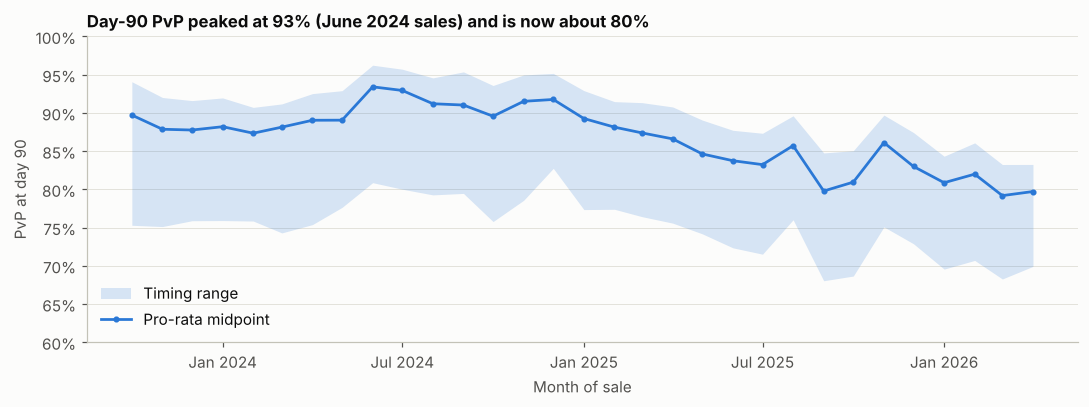

Whole portfolio, day 90: lower 75.0%, midpoint 86.5%, upper 90.3%  (23,765 contracts)


In [18]:
d90 = summarize(m90, "cohort")
d90 = d90.loc[d90["contracts"] >= MIN_COHORT_SIZE]
fig, ax = plt.subplots(figsize=(10, 3.8))
xt = d90.index.to_timestamp()
ax.fill_between(xt, d90["pvp_lower"], d90["pvp_upper"], color=BLUE, alpha=0.18, linewidth=0, label="Timing range")
ax.plot(xt, d90["pvp_mid"], color=BLUE, marker="o", markersize=3, label="Pro-rata midpoint")
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("PvP at day 90")
ax.set_xlabel("Month of sale")
ax.set_title("Day-90 PvP peaked at 93% (June 2024 sales) and is now about 80%")
date_axis(ax)
ax.legend(loc="lower left")
fig.tight_layout()
savefig(fig, "fig4_day90_by_cohort")
plt.show()

eligible90 = m90.loc[m90["eligible"]]
print("Whole portfolio, day 90: lower {:.1%}, midpoint {:.1%}, upper {:.1%}  ({:,} contracts)".format(
    eligible90.applied_lower.sum() / eligible90.due.sum(), eligible90.applied_mid.sum() / eligible90.due.sum(),
    eligible90.applied_upper.sum() / eligible90.due.sum(), len(eligible90)))

Share of contracts below 75% at day 90:

In [19]:
contract_90 = m90.assign(rate=m90["applied_mid"] / m90["due"]).merge(portfolio[["contract_id", "cohort_q"]], on="contract_id")
weak_start = contract_90.loc[contract_90["eligible"]].groupby("cohort_q")["rate"].apply(lambda r: (r < 0.75).mean())
display(save_table(weak_start.to_frame("share under 75% at day 90").T, "weak_start_share"))

cohort_q,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
share under 75% at day 90,0.152,0.196,0.152,0.118,0.118,0.191,0.252,0.263,0.208,0.243,0.239


- Midpoint peaked at 93% for June 2024 sales; about 80% for 2026 sales.
- Contracts below 75% at day 90: about 12% in H2 2024, 21–26% since Q2 2025.

## 7. KPIs 4–5: PvP and ownership at twice the term

Only 4,825 contracts have reached 2× term: the oldest sales plus short-term products. GOGLA also allows 1× and 1.5×
term as earlier milestones, which more contracts have reached.

In [20]:
milestones = {"Day 90": m90, "1× term": measure_at(portfolio["term_days"].to_numpy()),
              "1.5× term": measure_at(1.5 * portfolio["term_days"].to_numpy()), "2× term": m2x}
overall = []
for name, measured in milestones.items():
    e = measured.loc[measured["eligible"]]
    overall.append({"milestone": name, "contracts": len(e),
                    "PvP lower": e.applied_lower.sum() / e.due.sum(), "PvP upper": e.applied_upper.sum() / e.due.sum(),
                    "ownership (count)": e.owned.mean()})
overall = pd.DataFrame(overall).set_index("milestone")
display(save_table(overall, "milestones_overall"))

by_milestone = pd.concat({name: summarize(measured, "cohort_q")[["contracts", "pvp_lower", "pvp_upper", "ownership"]]
                          for name, measured in list(milestones.items())[1:]}, axis=1)
display(save_table(by_milestone, "milestones_by_quarter"))

,contracts,PvP lower,PvP upper,ownership (count)
milestone,,,,
Day 90,23765,0.750,0.903,0.004
1× term,14994,0.691,0.729,0.173
1.5× term,7790,0.874,0.883,0.682
2× term,4825,0.934,0.937,0.848


1× term                               1.5× term                                 2× term                              
         contracts pvp_lower pvp_upper ownership contracts pvp_lower pvp_upper ownership contracts pvp_lower pvp_upper ownership
cohort_q                                                                                                                        
2023Q4        1871     0.754     0.802     0.243      1871     0.902     0.912     0.751 1,869.000     0.943     0.945     0.871
2024Q1        1110     0.728     0.766     0.193      1110     0.867     0.878     0.651 1,029.000     0.909     0.912     0.784
2024Q2        1779     0.721     0.761     0.177      1779     0.857     0.863     0.625   757.000     0.939     0.943     0.795
2024Q3        2192     0.693     0.727     0.185      1338     0.874     0.880     0.652   270.000     0.963     0.967     0.919
2024Q4        2443     0.682     0.716     0.154       957     0.852     0.861     0.617   224.000     0.947     0.951     0.897
2025Q1        2870     0.661     0.700     0.134       254     0.946     0.965     0.866   254.000     0.978     0.980     0.969
2025Q2        2458     0.628     0.667     0.144       258     0.947     0.960     0.880   258.000     0.969     0.971     0.930
2025Q3         198     0.738     0.834     0.374       196     0.854     0.870     0.730   151.000     0.866     0.876     0.755
2025Q4          56     0.692     0.751     0.357        26     0.788     0.811     0.654    13.000     0.708     0.715     0.692
2026Q1          17     0.674     0.777     0.235         1     1.000     1.000     1.000       NaN       NaN       NaN       NaN

In [21]:
# which contracts have reached 2x term
twice = m2x.loc[m2x["eligible"]].merge(portfolio, on="contract_id")
twice["product group"] = np.where(twice["term_days"] <= 200, "Short-term products (≤200-day term)",
                                  np.where(twice["model_code"].isin(["Z17", "Z11", "Z15"]), twice["model_code"], "Other models"))
comp = twice.groupby("product group").agg(contracts=("due", "size"), first_sale=("purchase_date", "min"),
                                         last_sale=("purchase_date", "max"), due=("due", "sum"),
                                         applied=("applied_mid", "sum"), owned=("owned", "mean"),
                                         median_deposit=("deposit_share", "median"))
comp["PvP@2x"] = comp["applied"] / comp["due"]
display(save_table(comp.drop(columns=["due", "applied"]), "twice_term_composition"))

,contracts,first_sale,last_sale,owned,median_deposit,PvP@2x
product group,,,,,,
Other models,195,2023-10-01,2024-07-09,0.846,0.094,0.964
Short-term products (≤200-day term),1693,2023-10-01,2025-12-14,0.913,0.184,0.959
Z11,839,2024-01-20,2024-05-10,0.764,0.049,0.901
Z15,746,2023-10-01,2024-04-29,0.751,0.082,0.905
Z17,1352,2023-10-07,2024-05-07,0.875,0.068,0.961


In [22]:
bench = pd.DataFrame({
    "This company": [overall.loc["2× term", "PvP lower"], overall.loc["2× term", "ownership (count)"]],
    "GOGLA overall": [BENCH_PVP_2X["Overall sample"], BENCH_OR_2X],
    "GOGLA West Africa": [BENCH_PVP_2X["West Africa"], np.nan],
}, index=["Repayment at 2× term", "Ownership at 2× term"])
display(save_table(bench, "benchmarks"))

,This company,GOGLA overall,GOGLA West Africa
Repayment at 2× term,0.934,0.720,0.770
Ownership at 2× term,0.848,0.780,NaN


- At 2× term: PvP 93.4–93.7%, ownership 84.8%. GOGLA averages: 72% (West Africa 77%) and 78%.
- These contracts are 19% of the book and mostly old.
- At 1× term (about 15,000 contracts), PvP falls from 75–80% for Q4 2023 sales to 63–67% for Q2 2025 sales.
  Ownership at 1× falls from 24% to 14%.
- Benchmarks are context only: older KPI version, unweighted averages, other markets.

## 8. Does day 90 predict the final result?

GOGLA links day 90 to the 2× term result but says to check it for each company.

In [23]:
early = pd.DataFrame({"contract_id": portfolio["contract_id"], "status": portfolio["contract_status"],
                      "day90": m90["applied_mid"] / m90["due"], "eligible_2x": m2x["eligible"],
                      "applied_2x": m2x["applied_mid"], "due_2x": m2x["due"], "owned_2x": m2x["owned"]})
early["day-90 band"] = pd.cut(early["day90"], [-0.01, 0.5, 0.75, 0.9, 0.9999, 1.0],
                              labels=["<50%", "50-75%", "75-90%", "90-<100%", "100%"])
# outcome at 2x term, grouped by each contract's own day-90 PvP
cal = early.loc[early["eligible_2x"]].groupby("day-90 band", observed=True).agg(
    contracts=("due_2x", "size"), applied=("applied_2x", "sum"), due=("due_2x", "sum"),
    ownership_2x=("owned_2x", "mean"), repossessed=("status", lambda s: (s == "REPOSSESSED").mean()))
cal["PvP@2x"] = cal["applied"] / cal["due"]
display(save_table(cal[["contracts", "PvP@2x", "ownership_2x", "repossessed"]], "day90_calibration_contract"))

,contracts,PvP@2x,ownership_2x,repossessed
day-90 band,,,,
<50%,194,0.557,0.294,0.227
50-75%,620,0.815,0.590,0.037
75-90%,857,0.930,0.782,0.006
90-<100%,1077,0.976,0.914,0.004
100%,2077,0.992,0.971,0.000


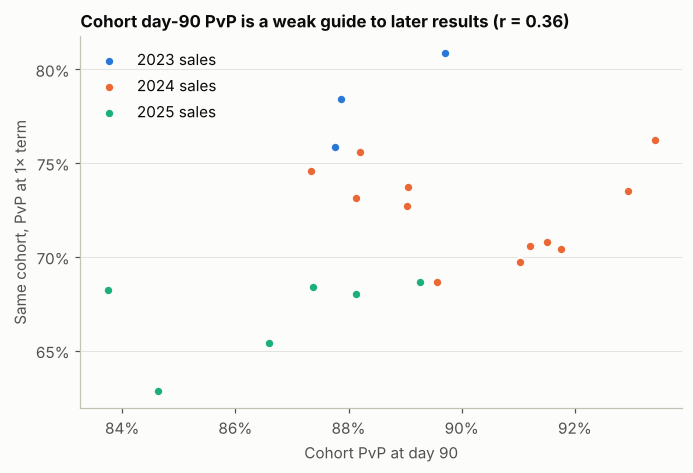

In [24]:
# cohort level: day-90 PvP vs PvP at 1x term
cohort_link = pd.DataFrame({"day90": summarize(m90, "cohort")["pvp_mid"],
                            "pvp_1x": summarize(milestones["1× term"], "cohort")["pvp_mid"],
                            "n_1x": summarize(milestones["1× term"], "cohort")["contracts"]}).dropna()
cohort_link = cohort_link.loc[cohort_link["n_1x"] >= MIN_COHORT_SIZE]
r = cohort_link["day90"].corr(cohort_link["pvp_1x"])
fig, ax = plt.subplots(figsize=(6.4, 4.4))
year_colour = {2023: BLUE, 2024: ORANGE, 2025: AQUA}
for year, colour in year_colour.items():
    sel = cohort_link.index.year == year
    ax.scatter(cohort_link.loc[sel, "day90"], cohort_link.loc[sel, "pvp_1x"], s=40, color=colour,
               edgecolor=SURFACE, linewidth=1.5, label=f"{year} sales", zorder=3)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.xaxis.set_major_locator(MultipleLocator(0.02))
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_xlabel("Cohort PvP at day 90")
ax.set_ylabel("Same cohort, PvP at 1× term")
ax.set_title(f"Cohort day-90 PvP is a weak guide to later results (r = {r:.2f})")
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "fig5_day90_vs_1x")
plt.show()

- Per contract, day 90 predicts well. Below 50% at day 90: 56% repaid, 29% owned and 23% repossessed at 2× term.
  100% at day 90: 99% repaid, 97% owned.
- Per cohort, it does not (r = 0.36). Mid-2024 cohorts had the best day 90 but fell behind during 2025. Cohorts
  should also be tracked at 50% and 100% of term.

## 9. Drivers

### 9.1 Calendar-time drop

Cash received ÷ instalments due, by calendar month, for contracts 15–90% through their term. If every cohort drops
in the same months, the cause is shared.

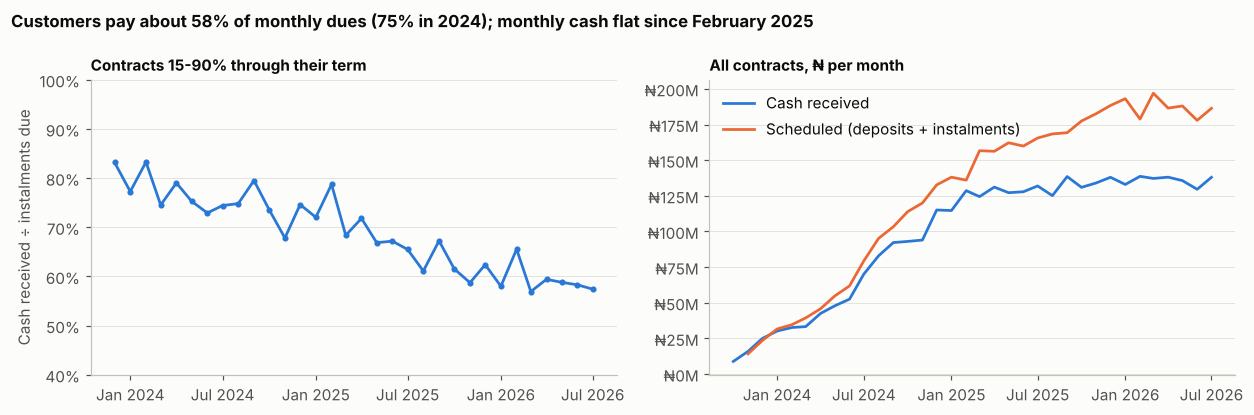

In [25]:
pay_rows = []
for i, month in enumerate(MONTHS[1:], start=1):
    month_end = month.to_timestamp(how="end").normalize()
    prev_end = MONTHS[i - 1].to_timestamp(how="end").normalize()
    t_now = (month_end - portfolio["purchase_date"]).dt.days.to_numpy()
    t_prev = (prev_end - portfolio["purchase_date"]).dt.days.to_numpy()
    elapsed = t_now / portfolio["term_days"].to_numpy()
    window = (t_prev >= 0) & (elapsed > 0.15) & (elapsed < 0.90)        # skip sale month and late stages
    due_in_month = due_at(portfolio, t_now) - due_at(portfolio, t_prev)
    cash_in_month = cum_cash[:, i] - cum_cash[:, i - 1]
    pay_rows.append({"month": month, "contracts": window.sum(), "cash": cash_in_month[window].sum(),
                     "due": due_in_month[window].sum(),
                     "scheduled_all": (due_at(portfolio, t_now) - due_at(portfolio, t_prev)).sum()
                     + portfolio.loc[portfolio["cohort"] == month, "deposit"].sum()})  # all instalments + deposits
pay = pd.DataFrame(pay_rows).set_index("month")
pay["pay rate"] = pay["cash"] / pay["due"]
pay = pay.loc[pay["contracts"] >= 500]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(pay.index.to_timestamp(), pay["pay rate"], color=BLUE, marker="o", markersize=3)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylim(0.4, 1.0)
axes[0].set_ylabel("Cash received ÷ instalments due")
axes[0].set_title("Contracts 15-90% through their term", fontsize=10)
date_axis(axes[0])
total = pd.DataFrame({"Receipts (all contracts)": monthly_cash.sum().to_numpy() / 1e6}, index=MONTHS.to_timestamp())
scheduled = pd.DataFrame(pay_rows).set_index("month")["scheduled_all"] / 1e6
axes[1].plot(total.index, total.iloc[:, 0], color=BLUE, label="Cash received")
axes[1].plot(scheduled.index.to_timestamp(), scheduled, color=ORANGE, label="Scheduled (deposits + instalments)")
axes[1].yaxis.set_major_formatter(naira_m)
axes[1].set_title("All contracts, ₦ per month", fontsize=10)
axes[1].legend(loc="upper left")
date_axis(axes[1])
fig.suptitle("Customers pay about 58% of monthly dues (75% in 2024); monthly cash flat since February 2025",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
savefig(fig, "fig6_calendar_pay_rate")
plt.show()

In [26]:
# same ratio for Z17, by calendar month and sales quarter
cohort_pay = []
for i, month in enumerate(MONTHS[1:], start=1):
    month_end = month.to_timestamp(how="end").normalize()
    prev_end = MONTHS[i - 1].to_timestamp(how="end").normalize()
    t_now = (month_end - portfolio["purchase_date"]).dt.days.to_numpy()
    t_prev = (prev_end - portfolio["purchase_date"]).dt.days.to_numpy()
    elapsed = t_now / portfolio["term_days"].to_numpy()
    window = (t_prev >= 0) & (elapsed > 0.15) & (elapsed < 0.90) & (portfolio["model_code"] == "Z17").to_numpy()
    frame = pd.DataFrame({"q": portfolio["cohort_q"], "cash": cum_cash[:, i] - cum_cash[:, i - 1],
                          "due": due_at(portfolio, t_now) - due_at(portfolio, t_prev)}).loc[window]
    g = frame.groupby("q").agg(cash=("cash", "sum"), due=("due", "sum"), n=("cash", "size"))
    g = g.loc[g["n"] >= MIN_COHORT_SIZE]
    for q, row in g.iterrows():
        cohort_pay.append({"month": str(month), "cohort": str(q), "rate": row.cash / row.due})
cohort_pay = pd.DataFrame(cohort_pay).pivot(index="month", columns="cohort", values="rate")
display(Markdown("**Z17: cash ÷ dues by calendar month (rows) and sales quarter (columns)**"))
display(save_table(cohort_pay.loc["2024-09":].round(2), "z17_pay_rate_calendar_by_cohort"))

**Z17: cash ÷ dues by calendar month (rows) and sales quarter (columns)**

cohort,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
month,,,,,,,,,,,
2024-09,0.810,0.790,0.930,0.850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-10,0.750,0.700,0.780,0.840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-11,0.670,0.690,0.740,0.740,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-12,NaN,0.690,0.750,0.780,0.800,NaN,NaN,NaN,NaN,NaN,NaN
2025-01,NaN,NaN,0.660,0.720,0.790,NaN,NaN,NaN,NaN,NaN,NaN
2025-02,NaN,NaN,0.810,0.800,0.890,NaN,NaN,NaN,NaN,NaN,NaN
2025-03,NaN,NaN,0.670,0.630,0.720,0.760,NaN,NaN,NaN,NaN,NaN
2025-04,NaN,NaN,0.700,0.660,0.730,0.770,NaN,NaN,NaN,NaN,NaN
2025-05,NaN,NaN,0.650,0.610,0.650,0.690,NaN,NaN,NaN,NaN,NaN


- Share of monthly dues paid: about 75% in 2024, about 58% in 2026.
- In March–May 2025 every Z17 cohort dropped at once (Q4 2024 sales: 0.89 to 0.65).
- Most new cohorts also start lower than the one before (Q4 2025 is the exception).
- Total cash has been flat at ₦125–140M a month since February 2025, while dues kept rising.
- The data do not show the cause. Questions for the company: prices, incomes and inflation, the move to agents,
  collection and lockout policy.

### 9.2 Channel, region and deposit

Raw averages mix in sales month and product. Weighted regression of each contract's day-90 PvP (weights = amount
due) with sales month and model fixed, standard errors clustered by sales month. Associations, not causes.

In [27]:
reg = portfolio.merge(m90[["contract_id", "eligible", "due", "applied_mid"]], on="contract_id")
reg = reg.loc[reg["eligible"]].copy()
reg["y"] = reg["applied_mid"] / reg["due"]
reg["cohort_s"] = reg["cohort"].astype(str)
reg["model_f"] = np.where(reg["model_code"].map(reg["model_code"].value_counts()) >= MIN_COHORT_SIZE, reg["model_code"], "small models")
reg["deposit_band"] = pd.cut(reg["deposit_share"], [-0.001, 0.0001, 0.05, 0.10, 1.0],
                             labels=["0%", "0-5%", "5-10%", ">10%"]).astype(str)


def fit(formula, data):
    """WLS weighted by amount due, SEs clustered by sales month."""
    groups = data["cohort_s"].astype("category").cat.codes
    return smf.wls(formula, data=data, weights=data["due"]).fit(cov_type="cluster", cov_kwds={"groups": groups})


def coef_table(result, pattern, label):
    """Coefficients matching `pattern`, in percentage points, with 95% CI."""
    est = result.params.filter(regex=pattern)
    se = result.bse.filter(regex=pattern)
    names = [n.split("[T.")[-1].rstrip("]") for n in est.index]
    return pd.DataFrame({"model": label, "vs": "", "difference (pts)": 100 * est.to_numpy(),
                         "95% CI low": 100 * (est - 1.96 * se).to_numpy(), "95% CI high": 100 * (est + 1.96 * se).to_numpy()},
                        index=names)


r_channel = fit("y ~ C(seller, Treatment('staff')) + C(region_f, Treatment('Region A')) + C(cohort_s) + C(model_f)", reg)
r_deposit = fit("y ~ C(deposit_band, Treatment('0-5%')) + np.log(cash_price) + C(seller) + C(cohort_s)", reg)
effects = pd.concat([
    coef_table(r_channel, "seller", "channel, vs staff").assign(vs="staff"),
    coef_table(r_channel, "region", "region, vs Region A").assign(vs="Region A"),
    coef_table(r_deposit, "deposit_band", "deposit, vs 0-5%").assign(vs="0-5% deposit"),
])
display(Markdown(f"**Adjusted differences in day-90 PvP, points** ({int(r_channel.nobs):,} contracts)"))
display(save_table(effects.drop(columns="model").round(1), "adjusted_differences_day90"))

**Adjusted differences in day-90 PvP, points** (23,765 contracts)

,vs,difference (pts),95% CI low,95% CI high
Unknown,staff,5.600,2.700,8.600
agent,staff,9.000,6.700,11.300
Region B,Region A,-3.500,-5.800,-1.200
Region C,Region A,-5.700,-13.900,2.400
Unknown,Region A,-2.000,-5.300,1.300
0%,0-5% deposit,-15.000,-19.800,-10.200
5-10%,0-5% deposit,-4.700,-8.300,-1.100
>10%,0-5% deposit,-3.000,-5.800,-0.200


In [28]:
# same channel model at 1x term
m1x = milestones["1× term"]
reg1 = portfolio.merge(m1x[["contract_id", "eligible", "due", "applied_mid", "owned"]], on="contract_id")
reg1 = reg1.loc[reg1["eligible"]].copy()
reg1["y"] = reg1["applied_mid"] / reg1["due"]
reg1["cohort_s"] = reg1["cohort"].astype(str)
reg1["model_f"] = np.where(reg1["model_code"].map(reg1["model_code"].value_counts()) >= MIN_COHORT_SIZE, reg1["model_code"], "small models")
r_channel_1x = fit("y ~ C(seller, Treatment('staff')) + C(region_f, Treatment('Region A')) + C(cohort_s) + C(model_f)", reg1)
display(Markdown(f"**PvP at 1× term, adjusted** ({int(r_channel_1x.nobs):,} contracts)"))
display(coef_table(r_channel_1x, "seller|region", "").drop(columns=["model", "vs"]).round(1))
raw_channel = reg1.groupby("seller").agg(contracts=("y", "size"), applied=("applied_mid", "sum"), due=("due", "sum"),
                                         ownership_1x=("owned", "mean"))
raw_channel["PvP@1x"] = raw_channel["applied"] / raw_channel["due"]
display(raw_channel[["contracts", "PvP@1x", "ownership_1x"]])

# Z17 day-90 by channel and quarter (cells with >= 50 contracts)
z17_90 = reg.loc[reg["model_code"] == "Z17"].groupby(["cohort_q", "seller"])[["applied_mid", "due"]].sum()
z17_channel = (z17_90["applied_mid"] / z17_90["due"]).unstack()
z17_n = reg.loc[reg["model_code"] == "Z17"].groupby(["cohort_q", "seller"]).size().unstack()
display(Markdown("**Z17 day-90 PvP by sales quarter and channel**"))
display(save_table(z17_channel.where(z17_n >= 50)[["agent", "staff"]].dropna(how="all"), "z17_channel_day90"))

**PvP at 1× term, adjusted** (14,994 contracts)

,difference (pts),95% CI low,95% CI high
Unknown,9.300,6.400,12.200
agent,10.800,9.000,12.700
Region B,-4.200,-6.500,-2.000
Region C,-0.400,-7.500,6.700
Unknown,12.500,7.300,17.600


,contracts,PvP@1x,ownership_1x
seller,,,
Unknown,1438,0.807,0.304
agent,8558,0.766,0.216
staff,4998,0.609,0.063


**Z17 day-90 PvP by sales quarter and channel**

seller,agent,staff
cohort_q,,
2023Q4,0.920,0.853
2024Q1,0.882,NaN
2024Q2,0.948,NaN
2024Q3,0.942,0.857
2024Q4,0.937,0.877
2025Q1,0.906,0.848
2025Q2,0.852,0.789
2025Q3,0.861,0.750
2025Q4,0.907,0.730


- Agents vs staff: +9 points at day 90, +11 at 1× term. Ownership at 1× term: 22% vs 6%. The gap shows in every
  Z17 quarter. All sales now go through agents; worth asking how agents are paid and how they screen customers.
- Region B: −3.5 points vs Region A. Region C: −6 points (270 contracts, wide interval).
- Zero deposit: −15 points vs a 0–5% deposit.
- 5–10% and >10% deposits: −3 to −5 points vs 0–5%. Deposit size mostly tracks product here, so this does not show
  that bigger deposits hurt.

### 9.3 New large and zero-deposit products

Day-90 PvP for products sold since July 2025.

In [29]:
recent_sales = portfolio["purchase_date"] >= "2025-07-01"
recent90 = m90.loc[m90["eligible"]].merge(portfolio.loc[recent_sales], on="contract_id")
by_model = recent90.groupby("model_code").agg(
    contracts=("due", "size"), tier=("tier", "first"), price_k=("cash_price", lambda s: s.median() / 1e3),
    deposit=("deposit_share", "median"), due=("due", "sum"), applied=("applied_mid", "sum"),
    repossessed=("contract_status", lambda s: (s == "REPOSSESSED").mean()))
by_model["PvP@90"] = by_model["applied"] / by_model["due"]
by_model = by_model.loc[by_model["contracts"] >= 50].sort_values("due", ascending=False)
display(save_table(by_model.drop(columns=["due", "applied"]), "recent_products_day90"))
grp = recent90.assign(group=np.where(recent90["tier_group"] == "Tier 4-5", "Tier 4-5", "Tier 1-3 and unknown")).groupby("group")
print((grp["applied_mid"].sum() / grp["due"].sum()).round(3).to_dict())

,contracts,tier,price_k,deposit,repossessed,PvP@90
model_code,,,,,,
Z37,3300,Tier 2,146.768,0.034,0.047,0.867
Z17,2980,Tier 1,114.077,0.039,0.047,0.850
Z12,376,Tier 4,422.538,0.073,0.056,0.658
Z04,67,Tier 5,"2,464.193",0.066,0.015,0.930
Z34,116,Tier 5,"2,116.562",0.000,0.147,0.682
Z29,65,Tier 5,"1,584.452",0.159,0.000,0.885
Z26,128,Tier 4,476.216,0.067,0.078,0.724
Z39,113,Tier 3,290.640,0.075,0.018,0.864
Z18,60,Tier 2,158.233,0.166,0.033,0.784


{'Tier 1-3 and unknown': 0.854, 'Tier 4-5': 0.777}


- Tier 4–5: 78% at day 90, vs 85% for smaller systems.
- Weakest: Z12 (66%), Z34 (68%, no deposit, 15% repossessed), Z26 (72%).
- Z04 (93%) and Z29 (89%, 16% deposit) show large systems can work with a deposit.

## 10. Lockouts, repossessions and ownership

`days_locked` is cumulative locked days to 10 August 2026. Its endpoint is not confirmed, so treat it as approximate.

In [30]:
portfolio["days_since_sale"] = (STATUS_DATE - portfolio["purchase_date"]).dt.days.clip(lower=1)
lock = portfolio.groupby("cohort_q").agg(contracts=("contract_id", "size"),
                                         locked_days=("days_locked", "sum"), days=("days_since_sale", "sum"),
                                         repossessed=("contract_status", lambda s: (s == "REPOSSESSED").mean()),
                                         owned=("contract_status", lambda s: (s == "PAID_OFF").mean()))
lock["share of days locked"] = lock["locked_days"] / lock["days"]
lock["locked now (of active)"] = portfolio.loc[active].groupby("cohort_q")["contract_status"].apply(lambda s: (s == "LOCKED").mean())
display(save_table(lock[["contracts", "share of days locked", "locked now (of active)", "repossessed", "owned"]], "lockouts_by_quarter"))
by_status = portfolio.assign(share=portfolio["days_locked"] / portfolio["days_since_sale"]).groupby("contract_status")["share"].median()
print("Median share of days locked, by status:", by_status.round(3).to_dict())

# outcomes by deposit share (raw, mixes product and term)
dep_band_all = pd.cut(portfolio["deposit_share"], [-0.001, 0.0001, 0.05, 0.10, 0.20, 1.0], labels=["0%", "0-5%", "5-10%", "10-20%", ">20%"])
display(save_table(portfolio.groupby(dep_band_all, observed=True).agg(
    contracts=("contract_id", "size"), repossessed=("contract_status", lambda s: (s == "REPOSSESSED").mean()),
    paid_off=("contract_status", lambda s: (s == "PAID_OFF").mean())), "deposit_band_outcomes"))

,contracts,share of days locked,locked now (of active),repossessed,owned
cohort_q,,,,,
2023Q4,1871,0.152,0.976,0.008,0.901
2024Q1,1110,0.217,0.888,0.025,0.798
2024Q2,1779,0.230,0.939,0.037,0.734
2024Q3,2195,0.259,0.786,0.026,0.584
2024Q4,2457,0.275,0.745,0.029,0.515
2025Q1,3391,0.306,0.712,0.033,0.405
2025Q2,3246,0.310,0.620,0.051,0.248
2025Q3,2742,0.295,0.481,0.040,0.077
2025Q4,1894,0.248,0.395,0.052,0.025


Median share of days locked, by status: {'LOCKED': 0.519, 'ON': 0.114, 'PAID_OFF': 0.056, 'REPOSSESSED': 0.035}


,contracts,repossessed,paid_off
deposit_share,,,
0%,358,0.123,0.151
0-5%,14580,0.044,0.185
5-10%,8514,0.025,0.506
10-20%,1760,0.013,0.780
>20%,473,0.004,0.934


- 51% of active customers were locked on 10 August (8,140 of 15,885).
- Q1–Q3 2025 buyers spent about 30% of their days locked; Q4 2023 buyers 15%.
- Repossessed: 0.8% of Q4 2023 sales, 4–5.5% of Q2 2025 – Q1 2026 sales. Zero deposit: 12%.
- 8,875 households (35%) own their system. The data do not show whether it still works.

## 11. Risk in the open book

Active = ON or LOCKED. Outstanding = price − cash received. Two PAR views: system days past due (company due date,
which moves during lockouts) and original-schedule arrears in days. Diagnostics only, not GOGLA KPIs.

In [31]:
book = portfolio.loc[active].copy()
book["outstanding"] = (book["cash_price"] - book["ledger_total"]).clip(lower=0)
book["arrears"] = book["due_to_date"] - book["applied_now"]
book["arrears_days"] = book["arrears"] / (book["instalment"] / book["period_days"])   # arrears in days of instalments
book["system_days"] = (STATUS_DATE - book["payment_due_date"]).dt.days.clip(lower=0)
par = pd.DataFrame({f"> {d} days": [book.loc[book["system_days"] > d, "outstanding"].sum() / book["outstanding"].sum(),
                                     book.loc[book["arrears_days"] > d, "outstanding"].sum() / book["outstanding"].sum()]
                    for d in [30, 90, 180]}, index=["PAR, system days past due", "PAR, original-schedule arrears"])
print(f"Active contracts {len(book):,}; outstanding ₦{book.outstanding.sum()/1e6:,.0f}M; "
      f"cumulative arrears ₦{book.arrears.sum()/1e6:,.0f}M")
display(save_table(par, "portfolio_at_risk"))

# no payment February-July 2026 (TA's inactivity rule)
window_cash = payments.loc[payments["payment_month"] >= "2026-02-01"].groupby("contract_id")["amount_paid"].sum()
inactive = ((portfolio["purchase_date"] < "2026-02-01") & (portfolio["contract_status"] != "PAID_OFF")
            & (portfolio["contract_id"].map(window_cash).fillna(0) == 0))
inactive_active = inactive & active
print(f"No payment February-July 2026: {inactive.sum():,} contracts "
      f"({portfolio.loc[inactive, 'contract_status'].value_counts().to_dict()}); "
      f"active ones hold ₦{(portfolio.cash_price - portfolio.ledger_total).clip(lower=0)[inactive_active].sum()/1e6:,.0f}M "
      f"= {(portfolio.cash_price - portfolio.ledger_total).clip(lower=0)[inactive_active].sum()/book.outstanding.sum():.0%} of active outstanding")

Active contracts 15,885; outstanding ₦1,976M; cumulative arrears ₦806M


,> 30 days,> 90 days,> 180 days
"PAR, system days past due",0.302,0.204,0.138
"PAR, original-schedule arrears",0.611,0.439,0.269


No payment February-July 2026: 2,844 contracts ({'LOCKED': 2211, 'REPOSSESSED': 622, 'ON': 11}); active ones hold ₦251M = 13% of active outstanding


In [32]:
# arrears buckets: share of the money owed, by days behind
bins = [-1, 0, 30, 90, 180, np.inf]
bucket_labels = ["Up to date", "1-30 days", "31-90 days", "91-180 days", "Over 180 days"]
buckets = pd.DataFrame({
    "company due date": book.groupby(pd.cut(book["system_days"], bins, labels=bucket_labels), observed=False)["outstanding"].sum(),
    "original plan": book.groupby(pd.cut(book["arrears_days"], bins, labels=bucket_labels), observed=False)["outstanding"].sum(),
}) / book["outstanding"].sum()
display(save_table(buckets, "arrears_buckets"))
lock_rate = (book["contract_status"] == "LOCKED").mean()
print(f"Lock rate (active contracts locked on 10 Aug 2026): {lock_rate:.1%}")

,company due date,original plan
Up to date,0.474,0.192
1-30 days,0.225,0.197
31-90 days,0.097,0.172
91-180 days,0.066,0.170
Over 180 days,0.138,0.269


Lock rate (active contracts locked on 10 Aug 2026): 51.2%


- ₦1.98bn outstanding on 15,885 active contracts.
- 30% is more than 30 system days late; 61% is more than 30 days behind the original plan; 27% more than 180 days.
- 2,222 active contracts (2,211 locked) paid nothing from February to July: 13% of the balance.
- By the original plan, 39% of the money owed is up to date or under 30 days behind; 27% is over 180 days behind.

### 11.1 Losses so far

The data have no write-off field. Repossessions are recorded; 6 months with no payment is used as a write-off proxy.

In [33]:
repo = portfolio["contract_status"] == "REPOSSESSED"
repo_unpaid = (portfolio.loc[repo, "cash_price"] - portfolio.loc[repo, "ledger_total"]).clip(lower=0)
losses = pd.Series({
    "repossessed contracts": repo.sum(),
    "repossessed share of all contracts": repo.mean(),
    "share of price paid before repossession": (portfolio.loc[repo, "ledger_total"] / portfolio.loc[repo, "cash_price"]).mean(),
    "unpaid price on repossessed contracts ₦M": repo_unpaid.sum() / 1e6,
    "active, no payment for 6 months (write-off proxy)": inactive_active.sum(),
    "owed by those contracts ₦M": (portfolio.cash_price - portfolio.ledger_total).clip(lower=0)[inactive_active].sum() / 1e6,
})
display(save_table(losses.to_frame("value"), "losses_summary"))

,value
repossessed contracts,925.000
repossessed share of all contracts,0.036
share of price paid before repossession,0.191
unpaid price on repossessed contracts ₦M,169.895
"active, no payment for 6 months (write-off proxy)","2,222.000"
owed by those contracts ₦M,250.882


- 925 contracts repossessed (3.6%). On average 19% of the price was paid first; ₦170M of price was unpaid (the
  resale value of the returned systems is not known).
- 2,222 active contracts paid nothing for 6 months and owe ₦251M. These are the likely write-offs.

## 12. Forecast of final repayment

- Split each contract into steps of 10% of its term.
- For each step and PvP band at the start of the step (<50%, 50–75%, 75–90%, 90–<100%, 100%), estimate the share
  of the unpaid balance collected in that step.
- Roll each open contract forward to 2× term. Paid off = 100%; repossessed = no more cash.

Backtest: leave one cohort out, forecast it to 1× (or 2×) term, compare with the actual result.

In [34]:
STEPS = 20
grid10 = {k: measure_at(k / 10 * portfolio["term_days"].to_numpy()) for k in range(1, STEPS + 1)}
# contract x step matrices: applied (A), due (D), reached (E), step date
A = np.column_stack([np.zeros(len(portfolio))] + [np.nan_to_num(grid10[k]["applied_mid"].to_numpy()) for k in range(1, STEPS + 1)])
D = np.column_stack([np.zeros(len(portfolio))] + [grid10[k]["due"].to_numpy() for k in range(1, STEPS + 1)])
E = np.column_stack([np.ones(len(portfolio), bool)] + [grid10[k]["eligible"].to_numpy() for k in range(1, STEPS + 1)])
STEP_DATE = np.column_stack([portfolio["purchase_date"].to_numpy()] + [grid10[k]["cutoff"].to_numpy() for k in range(1, STEPS + 1)])
BAND_EDGES = [0.5, 0.75, 0.9, 0.9999]


def band_of(a, d):
    """PvP band index 0-4."""
    return np.digitize(np.where(d > 0, a / np.maximum(d, 1), 1.0), BAND_EDGES)


def collection_rates(mask, since=None):
    """Share of unpaid balance collected per step and band; `since` keeps steps ending after a date."""
    rates = np.full((STEPS + 1, 5), np.nan)
    for k in range(1, STEPS):
        ok = E[:, k + 1] & mask
        if since is not None:
            ok = ok & (STEP_DATE[:, k + 1] >= np.datetime64(since))
        b = band_of(A[ok, k], D[ok, k])
        unpaid, gain = financed[ok] - A[ok, k], A[ok, k + 1] - A[ok, k]
        for j in range(5):
            sel = b == j
            if sel.sum() >= 30 and unpaid[sel].sum() > 0:
                rates[k, j] = gain[sel].sum() / unpaid[sel].sum()
    return pd.DataFrame(rates).ffill().bfill().to_numpy()   # fill thin cells from neighbours


def roll_forward(rates, start_step, start_applied, end_step=STEPS):
    """Apply the step rates from each contract's start step to `end_step`."""
    a = start_applied.copy()
    for k in range(1, end_step):
        go = k >= start_step
        b = band_of(a, D[:, k])
        step_gain = rates[k, b] * (financed - a)
        a = np.where(go, np.minimum(a + step_gain, D[:, k + 1]), a)   # cannot pass amount due
    return a


rates_all = collection_rates(np.ones(len(portfolio), bool))
display(Markdown("**Share of unpaid balance collected per 10%-of-term step, by PvP band**"))
display(save_table(pd.DataFrame(rates_all[1:STEPS], index=[f"{k*10}-{(k+1)*10}%" for k in range(1, STEPS)],
                                columns=["<50%", "50-75%", "75-90%", "90-<100%", "100%"]).iloc[::2], "collection_rates"))

**Share of unpaid balance collected per 10%-of-term step, by PvP band**

,<50%,50-75%,75-90%,90-<100%,100%
10-20%,0.040,0.061,0.081,0.089,0.103
30-40%,0.023,0.057,0.092,0.120,0.138
50-60%,0.024,0.068,0.122,0.170,0.186
70-80%,0.025,0.084,0.174,0.272,0.337
90-100%,0.025,0.111,0.300,0.656,0.949
110-120%,0.022,0.105,0.368,0.856,1.000
130-140%,0.016,0.076,0.288,0.690,1.000
150-160%,0.009,0.069,0.215,0.662,0.740
170-180%,0.007,0.049,0.193,0.601,1.000
190-200%,0.005,0.040,0.153,0.514,1.000


In [35]:
# backtest: leave the cohort out, forecast from 30/50/70% of term to 1x term
backtest = []
for q in ["2024Q1", "2024Q3", "2024Q4", "2025Q1", "2025Q2"]:
    in_q = (portfolio["cohort_q"] == pd.Period(q)).to_numpy()
    rates_loo = collection_rates(~in_q)
    test = in_q & E[:, 10]
    for k0 in [3, 5, 7]:
        projected = roll_forward(rates_loo, k0, A[:, k0], end_step=10)
        backtest.append({"cohort": q, "projected from": f"{k0*10}% of term", "target": "1× term", "contracts": test.sum(),
                         "projected": projected[test].sum() / financed[test].sum(),
                         "actual": A[test, 10].sum() / financed[test].sum()})
# and from 1x term to 2x term for the oldest cohorts
for q in ["2023Q4", "2024Q1", "2024Q2"]:
    in_q = (portfolio["cohort_q"] == pd.Period(q)).to_numpy()
    test = in_q & E[:, 20]
    projected = roll_forward(collection_rates(~in_q), 10, A[:, 10], end_step=20)
    backtest.append({"cohort": q, "projected from": "100% of term", "target": "2× term", "contracts": test.sum(),
                     "projected": projected[test].sum() / financed[test].sum(),
                     "actual": A[test, 20].sum() / financed[test].sum()})
backtest = pd.DataFrame(backtest)
backtest["error (pts)"] = 100 * (backtest["projected"] - backtest["actual"])
display(Markdown("**Backtest: forecast minus actual, points (positive = too high)**"))
display(save_table(backtest.pivot(index="cohort", columns="projected from", values="error (pts)")
                   [["30% of term", "50% of term", "70% of term", "100% of term"]].round(1), "projection_backtest"))
deteriorating = backtest["cohort"].isin(["2024Q3", "2024Q4", "2025Q1", "2025Q2"])
bias_by_start = backtest.loc[deteriorating].groupby("projected from")["error (pts)"].mean() / 100
print("Average over-projection for the 2024Q3-2025Q2 cohorts:", (100 * bias_by_start).round(1).to_dict())

**Backtest: forecast minus actual, points (positive = too high)**

projected from,30% of term,50% of term,70% of term,100% of term
cohort,,,,
2023Q4,NaN,NaN,NaN,-2.300
2024Q1,-0.400,-0.500,-0.500,-2.000
2024Q2,NaN,NaN,NaN,0.200
2024Q3,5.200,3.700,1.400,NaN
2024Q4,6.900,3.500,1.100,NaN
2025Q1,6.100,2.700,0.800,NaN
2025Q2,5.000,3.600,1.900,NaN


Average over-projection for the 2024Q3-2025Q2 cohorts: {'30% of term': 5.8, '50% of term': 3.4, '70% of term': 1.3}


- Accurate for a stable cohort (2024Q1: within 0.5 points); 0–2 points low from 1× to 2× term.
- Too high for declining cohorts: about 6 points from 30% of term, 3 from 50%, 1 from 70%.
- So I add a low case: forecast minus the backtest error for the cohort's current stage. Cohorts below 30% of
  term are not forecast.

In [36]:
kstar = np.array([np.flatnonzero(E[i]).max() for i in range(len(portfolio))])   # last step reached
start_applied = A[rows_all, kstar]
projected = roll_forward(rates_all, np.maximum(kstar, 1), np.where(kstar == 0, 0, start_applied))
status = portfolio["contract_status"].to_numpy()
projected = np.where(status == "PAID_OFF", financed, projected)                              # complete
projected = np.where(status == "REPOSSESSED", np.minimum(now_applied, financed), projected)  # no more cash
portfolio["projected_2x"] = projected
portfolio["step_now"] = kstar


def bias_for(step):
    """Backtest error for a cohort's current step (0 past 90% of term)."""
    if step >= 9:
        return 0.0
    if step >= 7:
        return bias_by_start["70% of term"]
    if step >= 5:
        return bias_by_start["50% of term"]
    if step >= 3:
        return bias_by_start["30% of term"]
    return np.nan


proj = portfolio.groupby("cohort_q").agg(financed=("amount_financed", "sum"), projected=("projected_2x", "sum"),
                                         median_step=("step_now", "median"))
proj["share of term reached (median)"] = proj["median_step"] / 10
proj["projected PvP@2x"] = proj["projected"] / proj["financed"]
proj["low case"] = proj["projected PvP@2x"] - proj["median_step"].map(bias_for)
actual2x = summarize(m2x, "cohort_q")
proj["already measured at 2x (eligible part)"] = actual2x["pvp_mid"]
proj.loc[proj["median_step"] < 3, ["projected PvP@2x", "low case"]] = np.nan   # too young
display(save_table(proj[["financed", "share of term reached (median)", "already measured at 2x (eligible part)",
                         "projected PvP@2x", "low case"]], "projection_by_quarter"))

proj_mask = proj["projected PvP@2x"].notna()
book_fin = proj.loc[proj_mask, "financed"].sum()
base_total = proj.loc[proj_mask, "projected"].sum() / book_fin
low_total = (proj.loc[proj_mask, "low case"] * proj.loc[proj_mask, "financed"]).sum() / book_fin
recent_2025 = proj.loc[[pd.Period(q) for q in ["2025Q1", "2025Q2", "2025Q3"]]]
print(f"Cohorts 2023Q4-2026Q1 (₦{book_fin/1e9:,.2f}bn financed): projected lifetime PvP {base_total:.1%}, low case {low_total:.1%}")
print(f"2025Q1-Q3 cohorts: projected {(recent_2025.projected.sum()/recent_2025.financed.sum()):.1%}, "
      f"low {(recent_2025['low case']*recent_2025.financed).sum()/recent_2025.financed.sum():.1%}")
print(f"Never collected on these cohorts: ₦{(1-base_total)*book_fin/1e6:,.0f}M to ₦{(1-low_total)*book_fin/1e6:,.0f}M "
      "(before any value from repossessed devices)")

# check: rates from the last 12 months only
rates_recent = collection_rates(np.ones(len(portfolio), bool), since=RECENT_WINDOW_START)
projected_recent = roll_forward(rates_recent, np.maximum(kstar, 1), np.where(kstar == 0, 0, start_applied))
projected_recent = np.where(status == "PAID_OFF", financed, projected_recent)
projected_recent = np.where(status == "REPOSSESSED", np.minimum(now_applied, financed), projected_recent)
in_proj = portfolio["cohort_q"].isin(proj.index[proj_mask]).to_numpy()
print(f"Same projection with collection rates from the last 12 months only: "
      f"{projected_recent[in_proj].sum()/financed[in_proj].sum():.1%} (all-history rates: {base_total:.1%})")

,financed,share of term reached (median),already measured at 2x (eligible part),projected PvP@2x,low case
cohort_q,,,,,
2023Q4,236494424,2.000,0.944,0.948,0.948
2024Q1,247405625,2.000,0.911,0.912,0.912
2024Q2,314552589,1.900,0.941,0.891,0.891
2024Q3,540307597,1.600,0.965,0.858,0.858
2024Q4,506482379,1.400,0.950,0.845,0.845
2025Q1,623951954,1.200,0.980,0.799,0.799
2025Q2,476265399,1.000,0.970,0.780,0.780
2025Q3,456832280,0.800,0.872,0.793,0.780
2025Q4,467961797,0.600,0.712,0.798,0.764


Cohorts 2023Q4-2026Q1 (₦4.49bn financed): projected lifetime PvP 82.8%, low case 81.5%
2025Q1-Q3 cohorts: projected 79.2%, low 78.8%
Never collected on these cohorts: ₦774M to ₦832M (before any value from repossessed devices)
Same projection with collection rates from the last 12 months only: 82.0% (all-history rates: 82.8%)


### Stress scenario

Customers keep paying at the 2026 rate. All future collection rates are cut by the fall in the monthly pay rate
(2026 average ÷ 2024 average, Section 9.1).

In [37]:
stress_factor = pay.loc[pay.index.year == 2026, "pay rate"].mean() / pay.loc[pay.index.year == 2024, "pay rate"].mean()
rates_stress = np.minimum(rates_all * stress_factor, 1.0)
projected_stress = roll_forward(rates_stress, np.maximum(kstar, 1), np.where(kstar == 0, 0, start_applied))
projected_stress = np.where(status == "PAID_OFF", financed, projected_stress)
projected_stress = np.where(status == "REPOSSESSED", np.minimum(now_applied, financed), projected_stress)
stress_total = projected_stress[in_proj].sum() / financed[in_proj].sum()

scenarios = pd.DataFrame({
    "repaid by 2x term": [base_total, low_total, stress_total],
}, index=["Base forecast", "Cautious (minus backtest error)", f"Stress (collection rates x {stress_factor:.2f})"])
scenarios["not repaid ₦M"] = (1 - scenarios["repaid by 2x term"]) * book_fin / 1e6
display(Markdown(f"**Cohorts Q4 2023 – Q1 2026, ₦{book_fin/1e9:,.2f}bn financed**"))
display(save_table(scenarios, "loss_scenarios"))

**Cohorts Q4 2023 – Q1 2026, ₦4.49bn financed**

,repaid by 2x term,not repaid ₦M
Base forecast,0.828,774.452
Cautious (minus backtest error),0.815,832.358
Stress (collection rates x 0.78),0.785,966.650


- Base: 82.8% repaid, ₦774M not repaid. Cautious: 81.5%, ₦832M.
- Stress (rates × 0.78): 78.5% repaid, ₦967M not repaid, about a fifth of the money lent.

### 12.1 Value of late payment

Present value of instalments received vs the original schedule, two oldest cohorts, at 20% and 30% a year (assumed
rates; the real cost of funds is not given).

In [38]:
def pv_ratio(mask, rate):
    """PV of received instalments ÷ PV of scheduled instalments, and the same ratio undiscounted."""
    ids = np.flatnonzero(mask)
    start = np.array([month_index[m] for m in portfolio["cohort"].iloc[ids]])
    net = np.minimum(np.clip(cum_cash[ids] - deposit[ids, None], 0, None), financed[ids, None])
    actual_flow = np.diff(np.concatenate([np.zeros((len(ids), 1)), net], axis=1), axis=1)
    sched = np.column_stack([due_at(portfolio.iloc[ids], np.clip(
        (m.to_timestamp(how="end").normalize() - portfolio["purchase_date"].iloc[ids]).dt.days.to_numpy(), -1, None))
        for m in MONTHS])
    sched_flow = np.diff(np.concatenate([np.zeros((len(ids), 1)), sched], axis=1), axis=1)
    months_from_sale = np.arange(len(MONTHS))[None, :] - start[:, None]
    disc = (1 + rate) ** (-months_from_sale / 12)
    return (actual_flow * disc).sum() / (sched_flow * disc).sum(), actual_flow.sum() / sched_flow.sum()


pv_rows = []
for q in ["2023Q4", "2024Q1"]:
    mask = (portfolio["cohort_q"] == pd.Period(q)).to_numpy()
    for rate in [0.20, 0.30]:
        pv, nominal = pv_ratio(mask, rate)
        pv_rows.append({"cohort": q, "discount rate": rate, "received ÷ scheduled (nominal)": nominal,
                        "received ÷ scheduled (present value)": pv})
display(save_table(pd.DataFrame(pv_rows).set_index(["cohort", "discount rate"]), "time_value"))

received ÷ scheduled (nominal)  received ÷ scheduled (present value)
cohort discount rate                                                                      
2023Q4 0.200                                   0.950                                 0.930
       0.300                                   0.950                                 0.922
2024Q1 0.200                                   0.913                                 0.893
       0.300                                   0.913                                 0.886

- Late payment costs about 2 more points of value, even for the best cohorts.
- Forecast: 2025 cohorts end at 78–80% of the amount financed (Q4 2025–Q1 2026: 73–80%), vs 91–95% for 2023–early
  2024 cohorts.
- About ₦0.8bn of the ₦4.5bn lent from Q4 2023 to Q1 2026 will not be repaid (before resale of repossessed systems).
- 78–80% is close to the GOGLA West Africa average (77%) and the illustrative 80% target.
- Rates from the last 12 months give almost the same forecast (82.0% vs 82.8%).

## 13. Decision

| Evidence | Finding |
|---|---|
| Finished contracts | 93–94% repaid, 85% owned at 2× term; above GOGLA averages. Mostly old loans. |
| Same product, same stage | Z17 at 90% of term: 80% (Q4 2023 sales) vs 60% (Q2–Q3 2025 sales). |
| Day 90 | 93% (June 2024 sales) to about 80% (2026). Weak starters 12% to about 24%. |
| Monthly payments | 75% of dues paid in 2024, 58% in 2026. All cohorts fell in March–May 2025. |
| New lending | About half Tier 4–5. Zero-deposit Z34: 68% at day 90, 15% repossessed. |
| Channel | Agents +9 to +11 points vs staff; now all sales. |
| Open book | ₦1.98bn outstanding; 51% of active customers locked. |
| Forecast | 2025 cohorts 78–80%; about ₦0.8bn not repaid. |
| Missing | Costs, funding, currency, device performance. |

**Decision: invest a smaller first amount now, with conditions. Add more only if new cohorts stop getting worse
over the next two quarters.**

Why not a full yes:

- The strong results come from 2023–early 2024 sales. New money funds loans like the 2025 ones (78–80%) or riskier
  ones.
- The decline has not stopped: 2026 day-90 results are among the lowest.
- No cost or funding data, so profit at 78–80% cannot be checked.

Why not a no:

- Lockouts work: Z17 Q4 2023 sales went from 81% at 1× term to 97% at 2×.
- 8,875 households own their system.
- The company moved to agents and has almost stopped zero-deposit loans (0.4% of July 2026 lending, 23% in Q1 2026).

Conditions:

1. **Use of funds:** no zero-deposit loans; cap Tier 4–5 (e.g. 25% of funds) until they reach 1× term; affordability
   checks for large systems.
2. **Targets for more money** (new monthly cohorts, daily data): day-90 PvP ≥ 85% (now about 80%); ≤ 15% of
   customers below 75% at day 90 (now about 24%); PvP ≥ 75% at half the term (2025 sales: 71–74%). Based on the
   company's own 2024 results, not GOGLA standards.
3. **Data before closing:** daily payments and allocation rules; repossession dates and resale values; costs and
   margins by product; funding and currency exposure; agent pay; device uptime and repairs.

The decision would change if the 2025 drop proves to be a one-off, or if costs are low enough to profit at 78–80%.

## 14. Checks

Confirm the numbers quoted above. They do not prove the company's records are right.

In [39]:
assert len(portfolio) == 25685 and len(payments) == 275172 and portfolio["contract_id"].is_unique
assert np.isclose(pvp_now, 0.764, atol=5e-4) and abs(pvp_now - pvp_snapshot) < 0.001
for measured in [m90, m2x, *grid_measures.values()]:
    e = measured.loc[measured["eligible"]]
    assert (e["applied_lower"] <= e["applied_mid"] + 1e-6).all() and (e["applied_mid"] <= e["applied_upper"] + 1e-6).all()
    assert measured.loc[~measured["eligible"], ["applied_lower", "applied_mid", "applied_upper", "owned"]].isna().all().all()
assert np.isclose(overall.loc["2× term", "ownership (count)"], 0.848, atol=5e-4)
assert np.isclose(overall.loc["2× term", "PvP lower"], 0.934, atol=5e-4)
assert np.isclose(vintage_z17.loc[pd.Period("2023Q4"), 0.9], 0.80, atol=0.01)
assert vintage_z17.loc[pd.Period("2025Q2"), 0.9] < 0.62
assert active.sum() == 15885 and (portfolio.loc[active, "contract_status"] == "LOCKED").sum() == 8140
assert (projected <= financed + 1e-6).all()
print("All checks passed.")

All checks passed.
